<a href="https://colab.research.google.com/github/Ibrahim-Hidayat/CodeAlpha_Iris_Classification/blob/main/Sales_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Advertising.csv")
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [16]:
df = df.drop(columns=["Unnamed: 0"])
print(df.shape)
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
df.describe().round(2)

(200, 4)
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
Duplicates: 0


,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


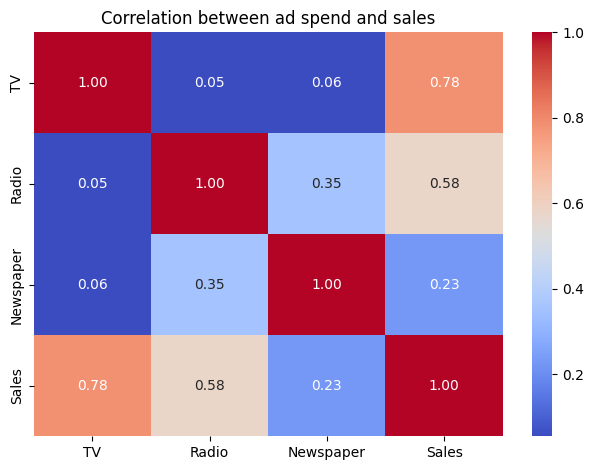

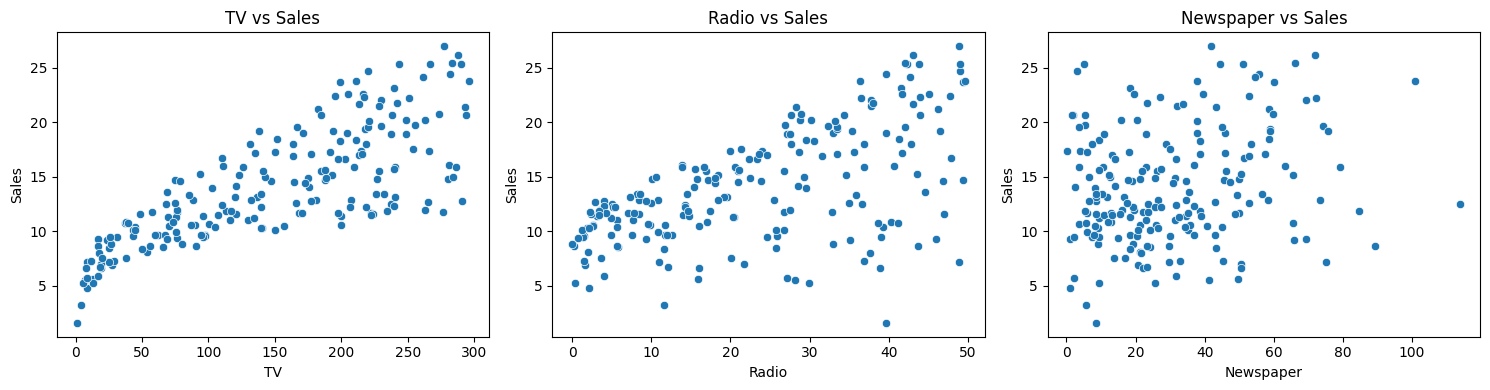

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between ad spend and sales")
plt.tight_layout()
plt.savefig("correlation.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.scatterplot(data=df, x=col, y="Sales", ax=ax)
    ax.set_title(f"{col} vs Sales")
plt.tight_layout()
plt.savefig("spend_vs_sales.png", dpi=200)
plt.show()

from google.colab import files
files.download("correlation.png")
files.download("spend_vs_sales.png")

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("R2:", round(r2_score(y_test, pred), 3))
print("MAE:", round(mean_absolute_error(y_test, pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
print(pd.Series(model.coef_, index=X.columns).round(4))

R2: 0.899
MAE: 1.461
RMSE: 1.782
TV           0.0447
Radio        0.1892
Newspaper    0.0028
dtype: float64


In [19]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

df["TV_x_Radio"] = df["TV"] * df["Radio"]

options = {
    "Linear (TV, Radio, Newspaper)": (LinearRegression(), ["TV", "Radio", "Newspaper"]),
    "Linear (TV, Radio)": (LinearRegression(), ["TV", "Radio"]),
    "Linear + TV x Radio": (LinearRegression(), ["TV", "Radio", "TV_x_Radio"]),
    "Random Forest": (RandomForestRegressor(random_state=42), ["TV", "Radio", "Newspaper"]),
}

for name, (m, cols) in options.items():
    scores = cross_val_score(m, df[cols], y, cv=5, scoring="r2")
    print(name, ":", round(scores.mean(), 3), "+/-", round(scores.std(), 3))

Linear (TV, Radio, Newspaper) : 0.887 +/- 0.04
Linear (TV, Radio) : 0.889 +/- 0.038
Linear + TV x Radio : 0.965 +/- 0.021
Random Forest : 0.976 +/- 0.009


In [20]:
base = pd.DataFrame({"TV": [150], "Radio": [25], "Newspaper": [30]})

for channel in ["TV", "Radio", "Newspaper"]:
    changed = base.copy()
    changed[channel] += 10
    gain = model.predict(changed)[0] - model.predict(base)[0]
    print(f"+10 on {channel}: sales change {gain:.2f}")

+10 on TV: sales change 0.45
+10 on Radio: sales change 1.89
+10 on Newspaper: sales change 0.03
